# Notebook 2 – Model Evaluation

## Mục tiêu

Notebook này đánh giá khả năng nhận diện khuôn mặt của mô hình FaceNet trên các ảnh đã thu thập.

Do tập dữ liệu hiện tại chủ yếu chỉ có một danh tính, notebook tập trung đánh giá mức độ mô hình nhận diện đúng người đó trong các điều kiện khác nhau. Notebook không tính Accuracy, Precision, F1-score hoặc FAR vì chưa có ảnh của danh tính khác để tạo mẫu đối chứng.

**Quy trình:** MTCNN phát hiện và căn chỉnh khuôn mặt → FaceNet tạo embedding → Cosine Similarity so sánh với ảnh tham chiếu → đối chiếu với ngưỡng `0.7`.

## 1. Import thư viện

Sử dụng PyTorch và facenet-pytorch để chạy MTCNN, FaceNet; Pandas để quản lý kết quả và Seaborn để trực quan hóa.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F

from PIL import Image
from pathlib import Path
from facenet_pytorch import MTCNN, InceptionResnetV1

# Thiết lập giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Chọn GPU nếu có, nếu không thì sử dụng CPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang sử dụng:", device)

Thiết bị đang sử dụng: cpu


## 2. Khởi tạo mô hình và đọc dữ liệu

- **MTCNN:** phát hiện và căn chỉnh khuôn mặt, đưa ảnh về kích thước đầu vào phù hợp.
- **FaceNet:** chuyển khuôn mặt thành vector đặc trưng embedding 512 chiều.
- **Ảnh tham chiếu:** ảnh chuẩn được dùng để so sánh với các ảnh trong tập dữ liệu.

Ngưỡng nhận diện được giữ giống chương trình `lab_5.py`: `0.7`.

In [2]:
# Xác định đường dẫn dữ liệu dựa trên vị trí notebook
data_dir = Path("../data/collected")
if not data_dir.exists():
    data_dir = Path("data/collected")

reference_path = data_dir.parent / "reference" / "reference.jpg"
metadata_path = data_dir / "metadata.csv"

# Đọc metadata, file hiện tại không có dòng tiêu đề
columns = [
    "filename", "condition", "timestamp",
    "face_width", "face_height", "brightness", "confidence"
]
df = pd.read_csv(metadata_path, header=None, names=columns)

# Khởi tạo MTCNN và FaceNet
mtcnn = MTCNN(
    image_size=160,
    margin=0,
    keep_all=False,
    device=device
)

facenet = InceptionResnetV1(pretrained="vggface2").eval().to(device)

# Kiểm tra ảnh tham chiếu có tồn tại hay không
print("Đường dẫn ảnh tham chiếu:", reference_path)
print("Số ảnh trong metadata:", len(df))
print("Ngưỡng nhận diện:", 0.7)

Đường dẫn ảnh tham chiếu: ..\data\reference\reference.jpg
Số ảnh trong metadata: 160
Ngưỡng nhận diện: 0.7


## 3. Tạo embedding cho ảnh tham chiếu

Embedding là vector đặc trưng số học đại diện cho khuôn mặt. FaceNet tạo embedding cho ảnh tham chiếu để làm cơ sở so sánh với các ảnh còn lại.

In [3]:
# Đọc ảnh tham chiếu và chuyển sang RGB
reference_image = Image.open(reference_path).convert("RGB")

# Phát hiện và căn chỉnh khuôn mặt trong ảnh tham chiếu
reference_face = mtcnn(reference_image)

if reference_face is None:
    raise ValueError("Không phát hiện được khuôn mặt trong ảnh tham chiếu.")

# Tạo embedding cho ảnh tham chiếu
with torch.no_grad():
    reference_embedding = facenet(reference_face.unsqueeze(0).to(device))

print("Kích thước embedding:", reference_embedding.shape)

Kích thước embedding: torch.Size([1, 512])


## 4. Tính Cosine Similarity cho tập ảnh

Cosine Similarity đo mức độ tương đồng giữa hai vector embedding.

- Giá trị càng gần 1: hai khuôn mặt càng tương đồng.
- Giá trị thấp hơn: mức độ tương đồng giảm.

Mỗi ảnh trong tập dữ liệu được so sánh với embedding của ảnh tham chiếu. Ảnh không đọc được hoặc không phát hiện được khuôn mặt sẽ được bỏ qua và ghi nhận trong quá trình xử lý.

In [4]:
from pathlib import Path

# Lấy thư mục gốc lab_5
project_dir = Path.cwd().parent

# Tìm tất cả ảnh trong project
image_extensions = [".jpg", ".jpeg", ".png"]

images = [
    file for file in project_dir.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("Thư mục đang tìm:", project_dir)
print("Tổng số ảnh tìm thấy:", len(images))

for image in images[:30]:
    print(image)

Thư mục đang tìm: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5
Tổng số ảnh tìm thấy: 161
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\reference\reference.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0001.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0002.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0003.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0004.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0005.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0006.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0007.jpg
c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_5\data\collected\bright\bright_0008.jpg
c:\Users\LENOVO\OneDriv

In [5]:
results = []

# Duyệt qua từng ảnh trong metadata
for _, row in df.iterrows():
    image_path = data_dir / str(row["condition"]) / str(row["filename"])

    try:
        # Đọc ảnh và chuyển sang RGB
        image = Image.open(image_path).convert("RGB")

        # Phát hiện và căn chỉnh khuôn mặt
        face = mtcnn(image)

        # Bỏ qua ảnh nếu MTCNN không phát hiện được khuôn mặt
        if face is None:
            continue

        # Tạo embedding và tính độ tương đồng với ảnh tham chiếu
        with torch.no_grad():
            embedding = facenet(face.unsqueeze(0).to(device))
            similarity = F.cosine_similarity(
                reference_embedding,
                embedding
            ).item()

        # Lưu kết quả của ảnh
        results.append({
            "filename": row["filename"],
            "condition": row["condition"],
            "similarity": similarity
        })

    except Exception as error:
        print("Không xử lý được ảnh:", image_path, "-", error)

# Chuyển kết quả thành DataFrame
results_df = pd.DataFrame(results)

print("Số ảnh xử lý thành công:", len(results_df))
print("Số ảnh không xử lý được:", len(df) - len(results_df))
display(results_df.head())

Số ảnh xử lý thành công: 158
Số ảnh không xử lý được: 2


,filename,condition,similarity
0,normal_0001.jpg,normal,0.906103
1,normal_0002.jpg,normal,0.906549
2,normal_0003.jpg,normal,0.901517
3,normal_0004.jpg,normal,0.911596
4,normal_0005.jpg,normal,0.922122


## 5. Đánh giá kết quả nhận diện

Sử dụng ngưỡng `0.7` giống chương trình nhận diện thời gian thực. Nếu Cosine Similarity lớn hơn hoặc bằng ngưỡng, ảnh được xem là nhận diện trùng với ảnh tham chiếu; ngược lại, ảnh được phân loại là Unknown.

Vì các ảnh trong tập dữ liệu đều thuộc cùng một người, tỷ lệ bên dưới là **tỷ lệ chấp nhận ảnh cùng danh tính (Genuine Acceptance Rate – GAR)** trên tập ảnh đã thu thập. Đây không phải Accuracy tổng quát của hệ thống.

In [6]:
# Thiết lập ngưỡng giống chương trình lab_5.py
THRESHOLD = 0.7

if results_df.empty:
    raise ValueError("Không có ảnh hợp lệ để đánh giá. Hãy kiểm tra đường dẫn và dữ liệu.")

# Phân loại kết quả dựa trên ngưỡng Cosine Similarity
results_df["prediction"] = results_df["similarity"].apply(
    lambda score: "Matched" if score >= THRESHOLD else "Unknown"
)

# Tính tỷ lệ ảnh cùng danh tính được chấp nhận
matched_count = (results_df["prediction"] == "Matched").sum()
total_count = len(results_df)
gar = matched_count / total_count * 100

print("Ngưỡng nhận diện:", THRESHOLD)
print("Số ảnh được nhận diện:", matched_count)
print("Tổng số ảnh đánh giá:", total_count)
print(f"Genuine Acceptance Rate (GAR): {gar:.2f}%")

display(results_df.head(10))

Ngưỡng nhận diện: 0.7
Số ảnh được nhận diện: 126
Tổng số ảnh đánh giá: 158
Genuine Acceptance Rate (GAR): 79.75%


,filename,condition,similarity,prediction
0,normal_0001.jpg,normal,0.906103,Matched
1,normal_0002.jpg,normal,0.906549,Matched
2,normal_0003.jpg,normal,0.901517,Matched
3,normal_0004.jpg,normal,0.911596,Matched
4,normal_0005.jpg,normal,0.922122,Matched
5,normal_0006.jpg,normal,0.908473,Matched
6,normal_0007.jpg,normal,0.882401,Matched
7,normal_0008.jpg,normal,0.879079,Matched
8,normal_0009.jpg,normal,0.900512,Matched
9,normal_0010.jpg,normal,0.885514,Matched


In [7]:
# Thống kê kết quả nhận diện theo từng điều kiện
condition_stats = results_df.groupby("condition").agg(
    total_images=("similarity", "count"),
    matched_images=("prediction", lambda x: (x == "Matched").sum()),
    average_similarity=("similarity", "mean"),
    min_similarity=("similarity", "min"),
    max_similarity=("similarity", "max")
)

# Tính tỷ lệ nhận diện
condition_stats["recognition_rate"] = (
    condition_stats["matched_images"]
    / condition_stats["total_images"] * 100
)

display(condition_stats.round(3))

,total_images,matched_images,average_similarity,min_similarity,max_similarity,recognition_rate
condition,,,,,,
bright,20,20,0.890,0.861,0.921,100.0
expression,20,20,0.875,0.850,0.906,100.0
far,20,20,0.890,0.860,0.918,100.0
left,18,0,0.539,0.386,0.655,0.0
low_light,20,20,0.857,0.813,0.901,100.0
near,20,20,0.813,0.788,0.852,100.0
normal,20,20,0.907,0.842,0.938,100.0
right,20,6,0.665,0.527,0.875,30.0


## 6. So sánh tỷ lệ nhận diện theo điều kiện

Tính tỷ lệ ảnh được nhận diện là Matched trong từng điều kiện. Qua đó có thể quan sát điều kiện ánh sáng, khoảng cách và góc mặt ảnh hưởng như thế nào đến kết quả so sánh với ảnh tham chiếu.

,total_images,matched_images,recognition_rate
condition,,,
bright,20,20,100.0
expression,20,20,100.0
far,20,20,100.0
left,18,0,0.0
low_light,20,20,100.0
near,20,20,100.0
normal,20,20,100.0
right,20,6,30.0


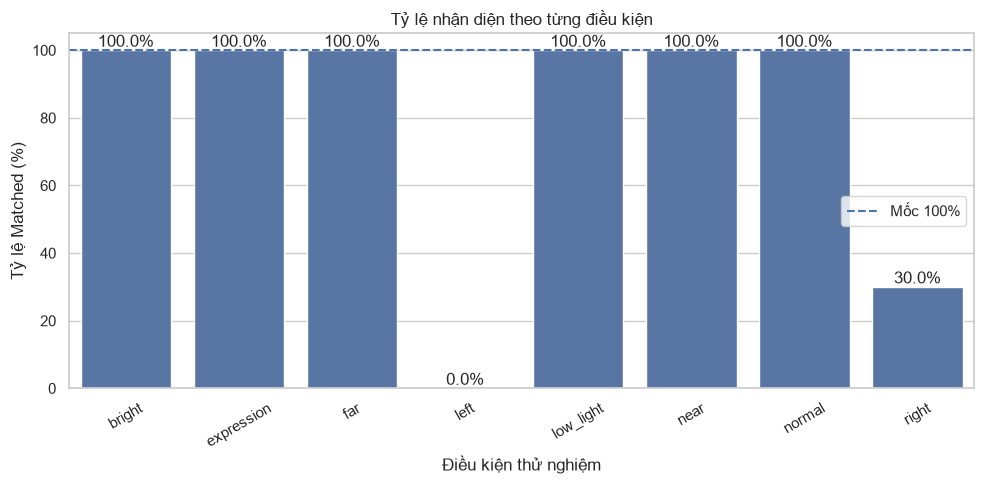

In [8]:
# Tính tổng số ảnh và số ảnh Matched theo từng điều kiện
condition_evaluation = results_df.groupby("condition").agg(
    total_images=("prediction", "count"),
    matched_images=("prediction", lambda x: (x == "Matched").sum())
)

# Tính tỷ lệ nhận diện thành công theo phần trăm
condition_evaluation["recognition_rate"] = (
    condition_evaluation["matched_images"] /
    condition_evaluation["total_images"] * 100
)

display(condition_evaluation.round(2))

# Vẽ biểu đồ tỷ lệ nhận diện theo điều kiện
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=condition_evaluation.index,
    y=condition_evaluation["recognition_rate"]
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Mốc 100%"
)
plt.title("Tỷ lệ nhận diện theo từng điều kiện")
plt.xlabel("Điều kiện thử nghiệm")
plt.ylabel("Tỷ lệ Matched (%)")
plt.ylim(0, 105)
plt.xticks(rotation=30)
plt.legend()

# Hiển thị phần trăm trên đầu mỗi cột
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

## 7. Kết luận

Notebook đã sử dụng MTCNN để phát hiện khuôn mặt, FaceNet để tạo embedding và Cosine Similarity để so sánh ảnh thu thập với ảnh tham chiếu.

Tỷ lệ GAR cho biết phần trăm ảnh cùng danh tính được hệ thống chấp nhận ở ngưỡng 0.7. Biểu đồ theo điều kiện giúp xác định những điều kiện mà mô hình có mức độ tương đồng thấp hơn.

**Giới hạn đánh giá:** Tập dữ liệu hiện chỉ có một danh tính, vì vậy kết quả chưa thể hiện khả năng phân biệt người dùng với người lạ. Muốn đánh giá đầy đủ hơn cần bổ sung ảnh của các danh tính khác và tạo các cặp so sánh khác người.

In [9]:
# Import Path to manage the output directory
from pathlib import Path

# Create results directory if it does not exist
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation results to CSV
results_df.to_csv(
    results_dir / "similarity_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!
